# E-Commerce Customer Segmentation using RFM, K-Means, DBSCAN, PCA and t-SNE

**Course:** CA-2 Viva | **Syllabus:** Unit-4 (Unsupervised Learning / Clustering) and Case Study

## Objective
Segment the customers of an online retailer using **RFM** (Recency, Frequency, Monetary) features and turn each segment into an actionable **marketing persona**.

## Pipeline
1. Load and clean transaction data
2. Engineer RFM features
3. Explore, log-transform and scale
4. **K-Means** (elbow, silhouette, Davies-Bouldin to choose *k*)
5. **DBSCAN** (k-distance plot, parameter grid, noise handling)
6. **PCA** for dimensionality reduction and visualization
7. **t-SNE** for non-linear visualization of segments
8. Compare algorithms
9. Profile clusters and derive marketing personas



## 1. Imports and settings

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

ModuleNotFoundError: No module named 'matplotlib'

## 2. Load data
We look for the UCI Online Retail file. Columns expected: `InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country`.

In [ ]:
def generate_synthetic_transactions(seed=RANDOM_STATE):
    """Synthetic online-retail transactions with the same schema as the UCI dataset.
    Several latent customer behaviours are simulated so clustering has real structure."""
    rng = np.random.default_rng(seed)
    end_date = pd.Timestamp("2011-12-09")
    # name, n_customers, base orders, extra poisson lam, last-order days range, history span, log-mean order value, log-sigma
    specs = [
        ("champ",   450, 15, 8, (1, 30),   364, np.log(120), 0.40),
        ("loyal",   700,  7, 3, (10, 90),  364, np.log(70),  0.40),
        ("new",     650,  1, 1, (1, 45),    45, np.log(50),  0.45),
        ("atrisk",  600,  6, 3, (120, 250), 364, np.log(80), 0.40),
        ("hibern",  600,  1, 1, (200, 364), 364, np.log(35), 0.50),
        ("whale",    25, 40, 20, (1, 20),   364, np.log(400), 0.50),
    ]
    rows, cid, inv = [], 12000, 500000
    for name, n, base, lam, (lo, hi), span, mu, sg in specs:
        for _ in range(n):
            cid += 1
            n_orders = base + rng.poisson(lam)
            last = rng.integers(lo, hi + 1)
            days = np.concatenate([[last], np.minimum(last + rng.uniform(0, span, n_orders - 1), 364)])
            for d in days:
                inv += 1
                value = rng.lognormal(mu, sg)
                qty = int(rng.integers(1, 20))
                rows.append((str(inv), "P%04d" % rng.integers(1, 3000), "ITEM", qty,
                             end_date - pd.Timedelta(days=float(d)), round(value / qty, 2), float(cid), "United Kingdom"))
    df = pd.DataFrame(rows, columns=["InvoiceNo", "StockCode", "Description", "Quantity",
                                     "InvoiceDate", "UnitPrice", "CustomerID", "Country"])
    # inject typical dirty records so the cleaning step is meaningful
    idx = rng.choice(df.index, size=int(0.03 * len(df)), replace=False)
    df.loc[idx[: len(idx) // 3], "CustomerID"] = np.nan                 # guest checkouts
    canc = df.loc[idx[len(idx) // 3: 2 * len(idx) // 3]].copy()          # cancellations
    canc["InvoiceNo"] = "C" + canc["InvoiceNo"]; canc["Quantity"] = -canc["Quantity"]
    df = pd.concat([df, canc], ignore_index=True)
    df.loc[idx[2 * len(idx) // 3:], "UnitPrice"] = 0                     # free / test items
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

candidates = ["data/online_retail.csv", "data/Online Retail.xlsx", "data/Online_Retail.xlsx",
              "online_retail.csv", "Online Retail.xlsx"]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    print("UCI file not found -> using synthetic transactions (same schema).")
    raw = generate_synthetic_transactions()
else:
    print("Loading", path)
    raw = pd.read_excel(path) if path.endswith("xlsx") else pd.read_csv(path, encoding="ISO-8859-1")
    raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])

print("Raw shape:", raw.shape)
raw.head()

UCI file not found -> using synthetic transactions (same schema).
Raw shape: (27003, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,515787,P0783,ITEM,7,2011-09-02 11:56:16.580193201,12.97,12987.0,United Kingdom
1,513219,P1848,ITEM,9,2010-12-10 00:00:00.000000000,18.27,12730.0,United Kingdom
2,516432,P1940,ITEM,13,2011-06-12 18:50:57.611637176,7.55,13051.0,United Kingdom
3,504565,P2019,ITEM,15,2011-07-01 08:10:45.326399488,7.67,12198.0,United Kingdom
4,511829,P2456,ITEM,1,2011-03-09 20:36:46.161278016,68.84,12593.0,United Kingdom


## 3. Data cleaning

In [ ]:
df = raw.copy()
print("Missing CustomerID :", df["CustomerID"].isna().sum())
print("Cancelled invoices :", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Qty <= 0           :", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0     :", (df["UnitPrice"] <= 0).sum())

df = df.dropna(subset=["CustomerID"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
print("\nClean shape:", df.shape, "| customers:", df["CustomerID"].nunique())

Missing CustomerID : 267
Cancelled invoices : 267
Qty <= 0           : 267
UnitPrice <= 0     : 268



Clean shape: (26201, 9) | customers: 3015


## 4. RFM feature engineering
- **Recency** – days since the customer's last purchase (lower = better)
- **Frequency** – number of distinct invoices
- **Monetary** – total spend

In [ ]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).round(2)
print("Snapshot date:", snapshot.date())
display(rfm.describe().T)

Snapshot date: 2011-12-09


,count,mean,std,min,25%,50%,75%,max
Recency,3015.0,112.092537,107.684579,1.00,23.0,55.00,209.00,364.00
Frequency,3015.0,8.690216,8.452896,1.00,2.0,8.00,11.00,65.00
Monetary,3015.0,1021.019277,2510.333261,7.79,97.9,601.31,880.11,30911.82


## 5. Exploratory analysis, transformation and scaling

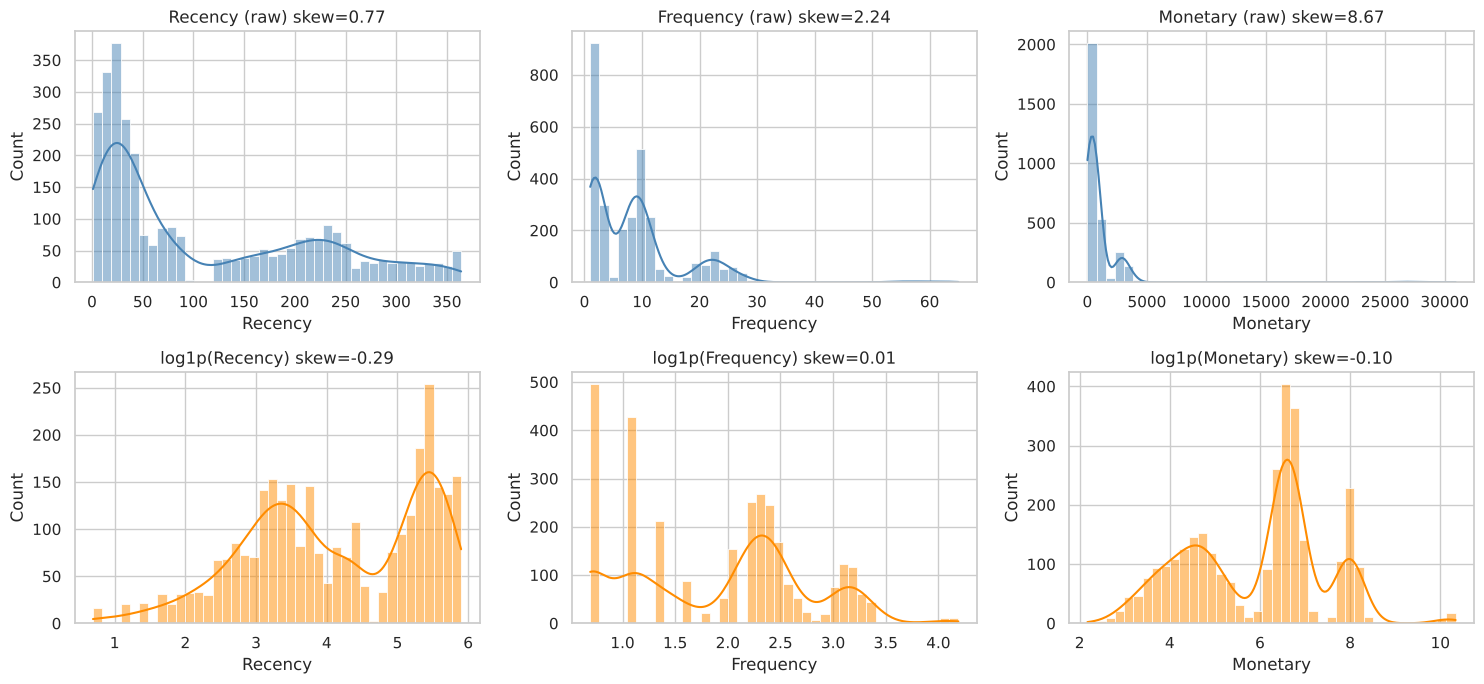

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, kde=True, ax=ax[0, i], color="steelblue")
    ax[0, i].set_title(f"{c} (raw) skew={rfm[c].skew():.2f}")
    sns.histplot(np.log1p(rfm[c]), bins=40, kde=True, ax=ax[1, i], color="darkorange")
    ax[1, i].set_title(f"log1p({c}) skew={np.log1p(rfm[c]).skew():.2f}")
plt.tight_layout(); savefig("01_rfm_distributions"); plt.show()

RFM features are strongly right-skewed. Distance-based algorithms (K-Means, DBSCAN) are sensitive to this, so we apply **log1p** and then **standardize**.

Scaled matrix: (3015, 3) | mean ~ [-0. -0.  0.] | std ~ [1. 1. 1.]


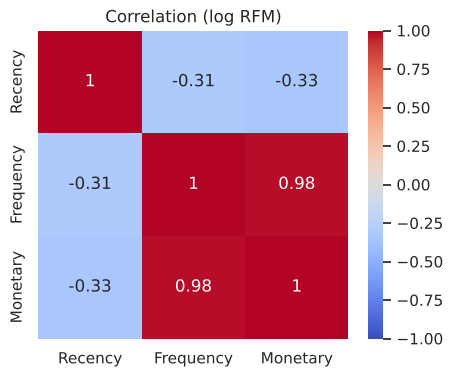

In [ ]:
X_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
print("Scaled matrix:", X.shape, "| mean ~", X.mean(0).round(3), "| std ~", X.std(0).round(3))

plt.figure(figsize=(5, 4))
sns.heatmap(X_log.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (log RFM)"); savefig("02_correlation"); plt.show()

## 6. K-Means clustering
We choose *k* using three criteria: **Elbow (inertia)**, **Silhouette** (higher better) and **Davies-Bouldin** (lower better).

,k,Inertia,Silhouette,DaviesBouldin,CalinskiHarabasz
0,2,4317.157,0.494,0.870,3299.623
1,3,2789.505,0.487,0.760,3377.222
2,4,1452.133,0.574,0.605,5247.940
3,5,1075.413,0.540,0.627,5576.567
4,6,944.985,0.510,0.795,5158.404
5,7,818.459,0.490,0.802,5039.031
6,8,721.714,0.459,0.847,4954.133
7,9,624.156,0.461,0.866,5069.696
8,10,520.511,0.467,0.808,5468.501


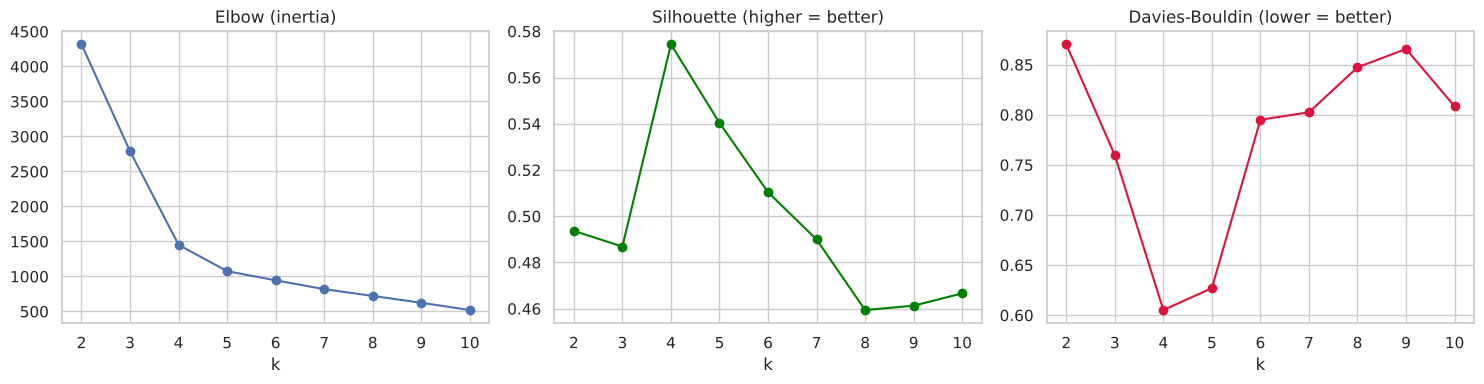

In [ ]:
ks = range(2, 11)
res = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    res.append((k, km.inertia_, silhouette_score(X, km.labels_),
                davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)))
km_res = pd.DataFrame(res, columns=["k", "Inertia", "Silhouette", "DaviesBouldin", "CalinskiHarabasz"])
display(km_res.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(km_res.k, km_res.Inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_res.k, km_res.Silhouette, "o-", color="green"); ax[1].set_title("Silhouette (higher = better)")
ax[2].plot(km_res.k, km_res.DaviesBouldin, "o-", color="crimson"); ax[2].set_title("Davies-Bouldin (lower = better)")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); savefig("03_kmeans_selection"); plt.show()

In [ ]:
# Choose k with best silhouette in a business-friendly range (3-7 segments)
cand = km_res[(km_res.k >= 3) & (km_res.k <= 7)]
K = int(cand.loc[cand.Silhouette.idxmax(), "k"])
print("Selected k =", K)

kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
rfm["KMeans"] = kmeans.labels_
print(rfm["KMeans"].value_counts().sort_index())
print(f"Silhouette={silhouette_score(X, kmeans.labels_):.3f}  DB={davies_bouldin_score(X, kmeans.labels_):.3f}")

Selected k = 4
KMeans
0    1230
1     589
2     551
3     645
Name: count, dtype: int64
Silhouette=0.574  DB=0.605


## 7. DBSCAN clustering
DBSCAN needs `eps` and `min_samples`. We use the **k-distance plot** to find the knee, then a small **grid search** that maximises silhouette while keeping 2-6 clusters and noise between 1 % and 15 % (so DBSCAN actually isolates outliers instead of absorbing everything into one blob).
Points that belong to no dense region are labelled **-1 (noise / outliers)**.

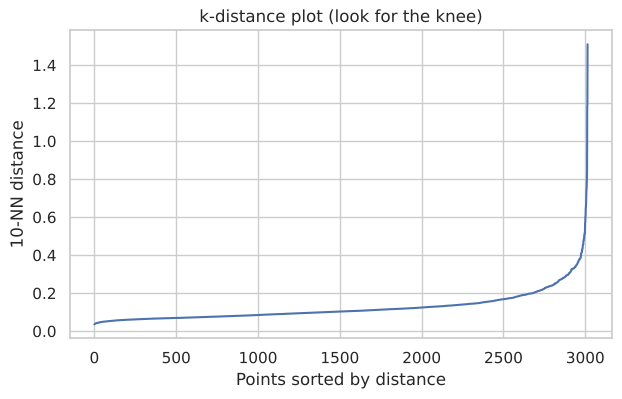

In [ ]:
min_s = 10
nn = NearestNeighbors(n_neighbors=min_s).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])
plt.figure(figsize=(7, 4))
plt.plot(kdist); plt.xlabel("Points sorted by distance"); plt.ylabel(f"{min_s}-NN distance")
plt.title("k-distance plot (look for the knee)"); savefig("04_kdistance"); plt.show()

In [ ]:
grid = []
for ms in [5, 10, 15, 20]:
    for eps in np.arange(0.2, 1.01, 0.05):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        ncl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).mean()
        sil = silhouette_score(X[lab != -1], lab[lab != -1]) if ncl >= 2 else np.nan
        grid.append((round(eps, 2), ms, ncl, round(noise * 100, 1), sil))
db_grid = pd.DataFrame(grid, columns=["eps", "min_samples", "clusters", "noise_%", "silhouette"])

ok = db_grid[(db_grid.clusters >= 2) & (db_grid.clusters <= 6) & (db_grid["noise_%"] >= 1) & (db_grid["noise_%"] <= 15)]
best = (ok if len(ok) else db_grid.dropna()).sort_values("silhouette", ascending=False).iloc[0]
display(ok.sort_values("silhouette", ascending=False).head(8).round(3))
print("Best parameters:\n", best)

,eps,min_samples,clusters,noise_%,silhouette
54,0.35,20,5,2.6,0.371
37,0.35,15,6,1.2,0.354
55,0.40,20,5,1.1,0.267


Best parameters:
 eps             0.350000
min_samples    20.000000
clusters        5.000000
noise_%         2.600000
silhouette      0.371081
Name: 54, dtype: float64


In [ ]:
EPS, MS = float(best.eps), int(best.min_samples)
dbscan = DBSCAN(eps=EPS, min_samples=MS).fit(X)
rfm["DBSCAN"] = dbscan.labels_
n_db = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
mask = dbscan.labels_ != -1
print(f"eps={EPS}, min_samples={MS} -> clusters={n_db}, noise={(~mask).sum()} ({(~mask).mean()*100:.1f}%)")
if n_db >= 2:
    print(f"Silhouette (non-noise) = {silhouette_score(X[mask], dbscan.labels_[mask]):.3f}")
print(rfm["DBSCAN"].value_counts().sort_index())

eps=0.35, min_samples=20 -> clusters=5, noise=77 (2.6%)
Silhouette (non-noise) = 0.371
DBSCAN
-1      77
 0     446
 1    1668
 2     234
 3     253
 4     337
Name: count, dtype: int64


## 8. PCA – dimensionality reduction
Even with only three features, PCA shows how much variance a 2-D view retains and which RFM combination drives each component.

Explained variance ratio: [0.718 0.274 0.007] | cumulative: [0.718 0.993 1.   ]


,PC1,PC2
Recency,-0.365,0.931
Frequency,0.657,0.271
Monetary,0.660,0.245


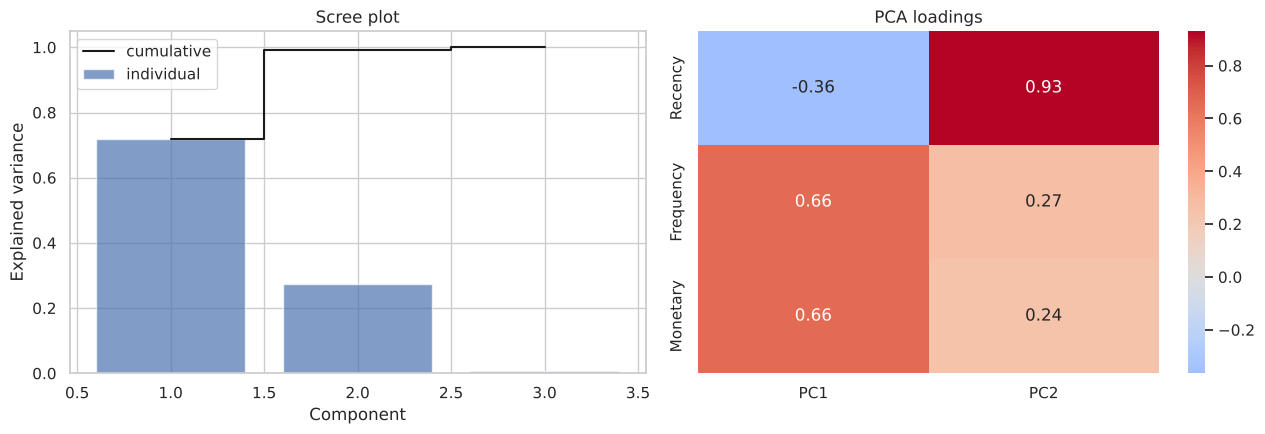

In [ ]:
pca_full = PCA().fit(X)
evr = pca_full.explained_variance_ratio_
print("Explained variance ratio:", evr.round(3), "| cumulative:", evr.cumsum().round(3))

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(X)
loadings = pd.DataFrame(pca.components_.T, index=["Recency", "Frequency", "Monetary"], columns=["PC1", "PC2"])
display(loadings.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, 4), evr, alpha=.7, label="individual"); ax[0].step(range(1, 4), evr.cumsum(), where="mid", color="k", label="cumulative")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance"); ax[0].legend(); ax[0].set_title("Scree plot")
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("PCA loadings")
plt.tight_layout(); savefig("05_pca_variance"); plt.show()

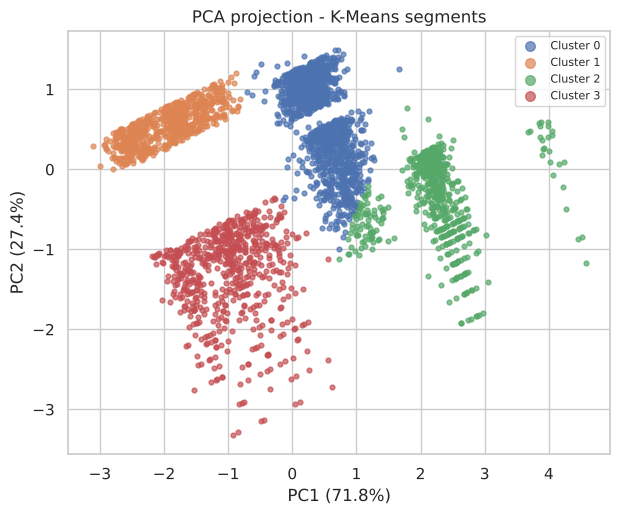

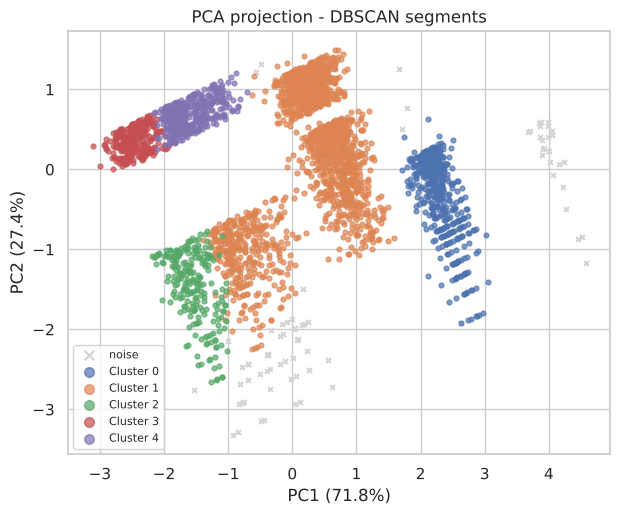

In [ ]:
def scatter2d(Z, labels, title, fname, xl, yl):
    plt.figure(figsize=(7, 5.5))
    for l in sorted(set(labels)):
        m = labels == l
        if l == -1:
            plt.scatter(Z[m, 0], Z[m, 1], c="lightgrey", s=12, marker="x", label="noise")
        else:
            plt.scatter(Z[m, 0], Z[m, 1], s=12, alpha=.7, label=f"Cluster {l}")
    plt.xlabel(xl); plt.ylabel(yl); plt.title(title); plt.legend(markerscale=2, fontsize=8)
    savefig(fname); plt.show()

pc_lbl = (f"PC1 ({evr[0]*100:.1f}%)", f"PC2 ({evr[1]*100:.1f}%)")
scatter2d(Xp, rfm["KMeans"].values, "PCA projection - K-Means segments", "06_pca_kmeans", *pc_lbl)
scatter2d(Xp, rfm["DBSCAN"].values, "PCA projection - DBSCAN segments", "07_pca_dbscan", *pc_lbl)

## 9. t-SNE – non-linear visualization
PCA preserves global linear variance, whereas **t-SNE** preserves local neighbourhoods and typically separates dense groups more clearly. t-SNE is used **only for visualization**, never for clustering or distances between clusters.

KL divergence: 0.43


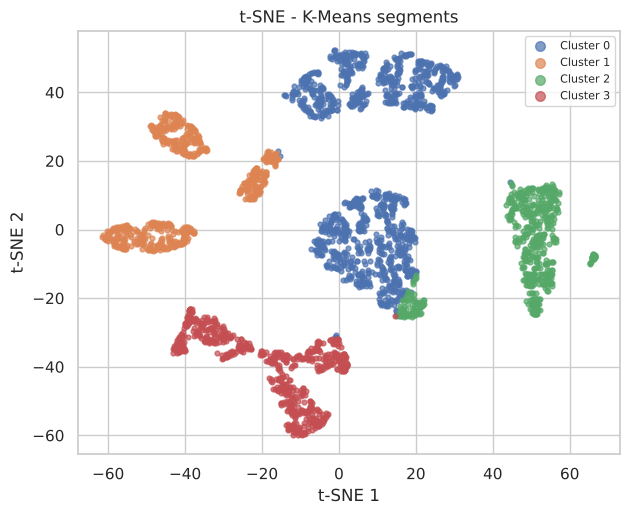

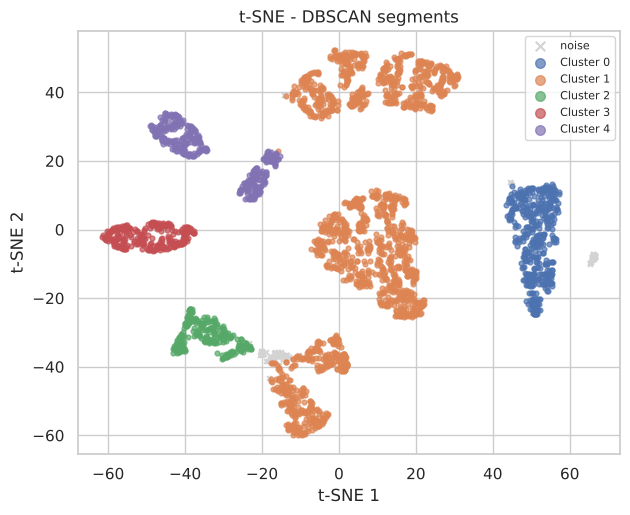

In [ ]:
tsne = TSNE(n_components=2, perplexity=40, learning_rate="auto", init="pca", random_state=RANDOM_STATE)
Xt = tsne.fit_transform(X)
print("KL divergence:", round(tsne.kl_divergence_, 3))
scatter2d(Xt, rfm["KMeans"].values, "t-SNE - K-Means segments", "08_tsne_kmeans", "t-SNE 1", "t-SNE 2")
scatter2d(Xt, rfm["DBSCAN"].values, "t-SNE - DBSCAN segments", "09_tsne_dbscan", "t-SNE 1", "t-SNE 2")

## 10. Algorithm comparison

In [ ]:
def metrics(labels):
    m = labels != -1
    if len(set(labels[m])) < 2: return [np.nan] * 3
    return [silhouette_score(X[m], labels[m]), davies_bouldin_score(X[m], labels[m]), calinski_harabasz_score(X[m], labels[m])]

cmp = pd.DataFrame({
    "K-Means": [K, 0.0] + metrics(rfm["KMeans"].values),
    "DBSCAN":  [n_db, (rfm["DBSCAN"] == -1).mean() * 100] + metrics(rfm["DBSCAN"].values),
}, index=["Clusters", "Noise %", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]).T
display(cmp.round(3))
print("Adjusted Rand Index between K-Means and DBSCAN:", round(adjusted_rand_score(rfm["KMeans"], rfm["DBSCAN"]), 3))

,Clusters,Noise %,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,4.0,0.000,0.574,0.605,5247.940
DBSCAN,5.0,2.554,0.371,0.690,2075.501


Adjusted Rand Index between K-Means and DBSCAN: 0.585


**Observations**
- **K-Means** partitions *every* customer, is fast and gives compact, business-friendly segments, but assumes roughly spherical clusters and is pulled by outliers.
- **DBSCAN** finds dense regions of arbitrary shape and explicitly isolates **outlier customers** as noise (very high spenders or unusual buyers) but is sensitive to `eps`/`min_samples` and struggles when densities differ.
- Practical choice: use **K-Means for the final marketing segments** and **DBSCAN to flag outliers** that deserve individual (VIP / key-account) treatment.

## 11. Cluster profiling

,Customers,Recency,Frequency,Monetary,TotalRevenue,Customers_%,Revenue_%
KMeans,,,,,,,
0,1230,120.7,9.2,743.6,914688.7,40.8,29.7
1,589,280.4,1.9,74.9,44117.7,19.5,1.4
2,551,16.0,22.6,3719.2,2049269.2,18.3,66.6
3,645,24.2,2.0,109.0,70297.6,21.4,2.3


,R_z,F_z,M_z
0,0.38,0.45,0.46
1,1.22,-1.09,-1.19
2,-1.16,1.38,1.34
3,-0.85,-1.04,-0.93


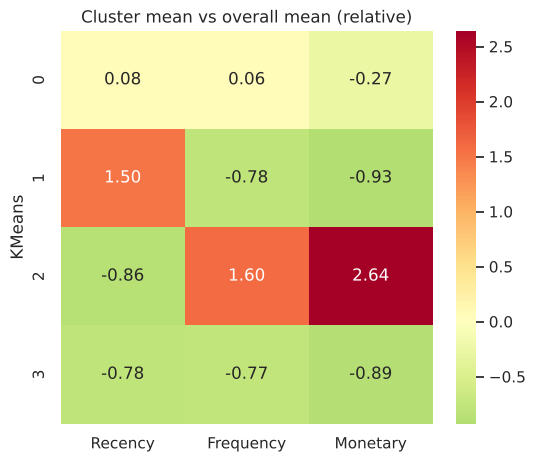

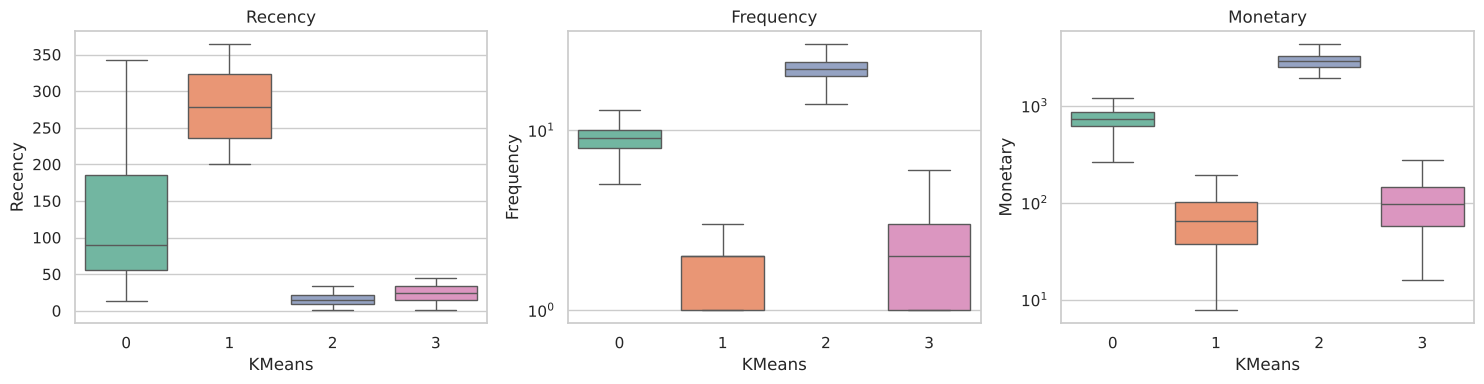

In [ ]:
profile = rfm.groupby("KMeans").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"), TotalRevenue=("Monetary", "sum"),
).round(1)
profile["Customers_%"] = (profile.Customers / profile.Customers.sum() * 100).round(1)
profile["Revenue_%"] = (profile.TotalRevenue / profile.TotalRevenue.sum() * 100).round(1)
display(profile)

# z-score of each cluster centre (in scaled log space): negative Recency z = more recent
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["R_z", "F_z", "M_z"]).round(2)
display(centers)

# Heatmap of relative importance
rel = (profile[["Recency", "Frequency", "Monetary"]] / rfm[["Recency", "Frequency", "Monetary"]].mean()) - 1
plt.figure(figsize=(6, 0.9 * K + 1.5))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn_r", center=0)
plt.title("Cluster mean vs overall mean (relative)"); savefig("10_cluster_heatmap"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=rfm, x="KMeans", y=c, ax=a, showfliers=False, palette="Set2"); a.set_title(c)
    if c != "Recency": a.set_yscale("log")
plt.tight_layout(); savefig("11_cluster_boxplots"); plt.show()

## 12. Marketing personas
Each cluster is named from its RFM centre (rule based), then linked to a persona description and a recommended marketing action.

In [ ]:
def name_cluster(r, f, m):
    if f > 0.5 and m > 0.5 and r < 0.2:   return "Champions"
    if f > 0 and r < 0.3:                  return "Loyal Customers"
    if f > 0 and r >= 0.3:                 return "At-Risk Loyalists"
    if f <= 0 and r < 0:                   return "New / Promising"
    return "Hibernating / Lost"

names = {}
for c, row in centers.iterrows():
    n = name_cluster(row.R_z, row.F_z, row.M_z)
    names[c] = n if n not in names.values() else f"{n} (C{c})"

playbook = {
    "Champions": ("Recent, frequent, high-spending buyers; the brand's best customers.",
                  "VIP / early-access programme, referral rewards, premium bundles; ask for reviews and UGC. Do NOT over-discount."),
    "Loyal Customers": ("Buy regularly and recently with solid basket value.",
                        "Loyalty points, cross-sell and upsell, subscription offers, personalised recommendations."),
    "At-Risk Loyalists": ("Used to buy often but have gone quiet recently.",
                          "Win-back emails ('we miss you'), time-limited coupons, survey to learn why they left, reminder of past favourites."),
    "New / Promising": ("Recent first-time or low-frequency buyers with growth potential.",
                        "Welcome series, onboarding tips, second-purchase incentive, free-shipping threshold, brand storytelling."),
    "Hibernating / Lost": ("Long inactive, low frequency, low spend.",
                           "Low-cost reactivation campaign, deep-discount last-chance offer, then suppress from paid campaigns to save budget."),
}
def lookup(n): return playbook[n.split(" (C")[0]]

rfm["Persona"] = rfm["KMeans"].map(names)
persona_tbl = profile.rename(index=names)[["Customers", "Customers_%", "Recency", "Frequency", "Monetary", "Revenue_%"]]
display(persona_tbl)

for c, n in names.items():
    desc, action = lookup(n)
    row = profile.loc[c]
    display(Markdown(
        f"### Cluster {c}: **{n}**  \n"
        f"*{int(row.Customers)} customers ({row['Customers_%']}%), {row['Revenue_%']}% of revenue | "
        f"avg Recency {row.Recency:.0f} days, Frequency {row.Frequency:.1f} orders, Monetary {row.Monetary:,.0f}*  \n"
        f"**Persona:** {desc}  \n**Action:** {action}"))

,Customers,Customers_%,Recency,Frequency,Monetary,Revenue_%
KMeans,,,,,,
At-Risk Loyalists,1230,40.8,120.7,9.2,743.6,29.7
Hibernating / Lost,589,19.5,280.4,1.9,74.9,1.4
Champions,551,18.3,16.0,22.6,3719.2,66.6
New / Promising,645,21.4,24.2,2.0,109.0,2.3


### Cluster 0: **At-Risk Loyalists**  
*1230 customers (40.8%), 29.7% of revenue | avg Recency 121 days, Frequency 9.2 orders, Monetary 744*  
**Persona:** Used to buy often but have gone quiet recently.  
**Action:** Win-back emails ('we miss you'), time-limited coupons, survey to learn why they left, reminder of past favourites.

### Cluster 1: **Hibernating / Lost**  
*589 customers (19.5%), 1.4% of revenue | avg Recency 280 days, Frequency 1.9 orders, Monetary 75*  
**Persona:** Long inactive, low frequency, low spend.  
**Action:** Low-cost reactivation campaign, deep-discount last-chance offer, then suppress from paid campaigns to save budget.

### Cluster 2: **Champions**  
*551 customers (18.3%), 66.6% of revenue | avg Recency 16 days, Frequency 22.6 orders, Monetary 3,719*  
**Persona:** Recent, frequent, high-spending buyers; the brand's best customers.  
**Action:** VIP / early-access programme, referral rewards, premium bundles; ask for reviews and UGC. Do NOT over-discount.

### Cluster 3: **New / Promising**  
*645 customers (21.4%), 2.3% of revenue | avg Recency 24 days, Frequency 2.0 orders, Monetary 109*  
**Persona:** Recent first-time or low-frequency buyers with growth potential.  
**Action:** Welcome series, onboarding tips, second-purchase incentive, free-shipping threshold, brand storytelling.

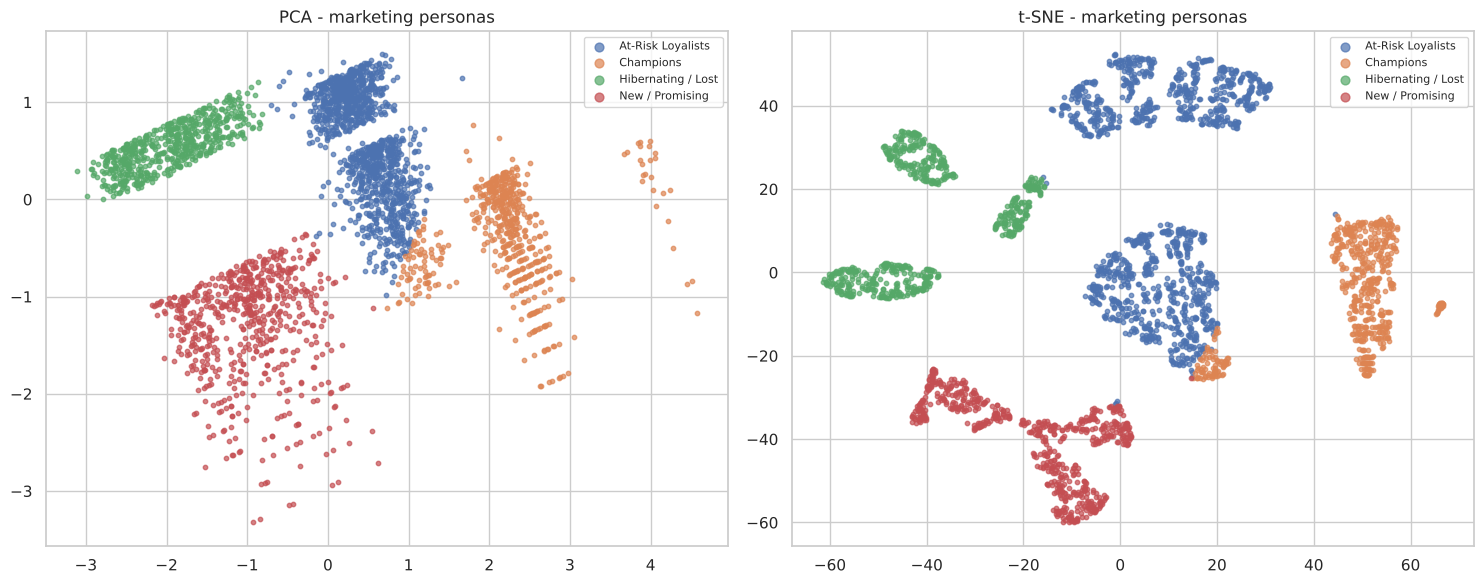

In [ ]:
# Final labelled visual: personas in PCA and t-SNE space
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for Z, a, t in [(Xp, ax[0], "PCA"), (Xt, ax[1], "t-SNE")]:
    for p in sorted(rfm["Persona"].unique()):
        m = (rfm["Persona"] == p).values
        a.scatter(Z[m, 0], Z[m, 1], s=10, alpha=.7, label=p)
    a.set_title(f"{t} - marketing personas"); a.legend(markerscale=2, fontsize=8)
plt.tight_layout(); savefig("12_personas"); plt.show()

## 13. Outliers flagged by DBSCAN

In [ ]:
outliers = rfm[rfm["DBSCAN"] == -1]
print(f"{len(outliers)} customers flagged as noise ({len(outliers)/len(rfm)*100:.1f}%)")
display(outliers.groupby("Persona")[["Recency", "Frequency", "Monetary"]].mean().round(1).assign(Count=outliers.groupby("Persona").size()))
display(outliers.sort_values("Monetary", ascending=False).head(10))

77 customers flagged as noise (2.6%)


,Recency,Frequency,Monetary,Count
Persona,,,,
At-Risk Loyalists,261.3,11.7,1198.4,3
Champions,15.2,54.0,23674.9,28
New / Promising,3.5,2.5,133.1,46


,Recency,Frequency,Monetary,KMeans,DBSCAN,Persona
CustomerID,,,,,,
15016,16,62,30911.82,2,-1,Champions
15009,9,65,30656.90,2,-1,Champions
15023,15,62,29636.45,2,-1,Champions
15007,18,62,28365.50,2,-1,Champions
15004,19,64,28287.57,2,-1,Champions
15003,12,56,27528.18,2,-1,Champions
15006,1,58,27399.48,2,-1,Champions
15010,2,63,26986.91,2,-1,Champions
15019,4,56,26934.65,2,-1,Champions


## 14. Save outputs

In [20]:
rfm.to_csv("outputs/rfm_segments.csv")
persona_tbl.to_csv("outputs/persona_summary.csv")
print("Saved outputs/rfm_segments.csv and outputs/persona_summary.csv; figures in ./figures")

Saved outputs/rfm_segments.csv and outputs/persona_summary.csv; figures in ./figures


## 15. Conclusion
- RFM features were cleaned, **log-transformed and standardized**, which was essential for distance-based clustering.
- **K-Means** (k chosen by elbow, silhouette and Davies-Bouldin) produced interpretable segments covering all customers.
- **DBSCAN** (parameters from the k-distance plot and a grid search) identified dense groups and isolated outlier customers.
- **PCA** explains how much variance a 2-D view keeps and shows that Frequency and Monetary dominate the first component, while **t-SNE** gives a clearer picture of local cluster separation.
- Each K-Means cluster was converted into a **marketing persona** with a concrete action (retain champions, grow loyal and new customers, win back at-risk loyalists, minimise spend on lost customers).

### Limitations and next steps
- Static RFM ignores product mix, returns and seasonality; add features such as average basket size and category preferences.
- Validate segments with an A/B test of the campaigns suggested above.
- Re-run the segmentation monthly because customer behaviour drifts.